# Recommender Systems — Lab Notebook (your copy)
**Mathematical Methods of AI · Weeks 2–3**

This notebook contains **Lab Tasks 1–5** (see the lab brief on Moodle). The prepared datasets,
file-loading code, temporal validation split and evaluation code are provided. Read this code
because a defense question may refer to any part of it. Complete the modeling and interpretation
parts marked `TODO(you)`. These cells raise `NotImplementedError` until you add working code.

| Where | What you must have |
|---|---|
| **Week 2, session 1** | Live instructor demo with Gift Cards, then Task 1 work and a short progress check |
| **Week 2, session 2** | Continue directly with Tasks 2-5 and any remaining progress checks. Both Week 2 sessions are mandatory and on campus |
| **Week 3, session 1** | Optional question clinic: attend on campus or through Teams; ask questions and continue improving the notebook |
| **Week 3, session 2 - first 10 min** | Submit the final notebook with saved outputs in Moodle; there is no separate lab report or spreadsheet |
| **Week 3, session 2 - next 60 min** | Mandatory written defense on campus; follow the resource rules below |

Rules: work is **individual**; use the category assigned by the instructor. Gift Cards is the
instructor's demo; AI assistants are allowed while preparing the lab, but not during the on-campus defense.
Questions are randomly assigned from the published categories. The defense checks that *you*
understand what you submitted. If you join the Week 3 clinic through
Teams, you are responsible for arriving on campus before the defense begins.

**What you may use during the defense:** your submitted notebook, printed question sheet and
ordinary documentation or reference pages. Use [DuckDuckGo without AI](https://noai.duckduckgo.com/)
for searches. No AI assistants (including Duck.ai), AI search answers, browser AI tools, messaging,
help from others or other notebook versions. Write answers in your own words and connect them to
your work.

Start the tasks during Week 2 and finish the remaining work between weeks.
The Week 3 clinic is for questions and corrections, not an additional required working session.
Complete the required tasks below. No extension tasks are needed.

## Environment check — run before the first lab

**JupyterHub:** open this notebook in the course Python environment and run the next two cells.
Your code runs on the server, even when you open JupyterHub from your own laptop. Do not install or
upgrade packages in the course environment yourself.

**Your own laptop (local Python):** run the same two cells. If packages are missing, run this command
in a separate notebook cell, then restart the kernel and repeat the check:

```python
%pip install "scikit-surprise==1.1.5" numpy pandas matplotlib scikit-learn
```

If the check fails, keep the complete error message and the Python information printed below.
Do not try random package upgrades or NumPy downgrades.
The lab reads local CSV files. Hugging Face, `datasets` and PyArrow are not required.

The check uses six made-up ratings. You should see package versions, three model predictions, a
small plot and **Local environment checks passed**. Then test loading your
assigned dataset in the environment you will use in class. On JupyterHub, upload and extract the ZIP
there: files on your laptop are not automatically available to the server.

In [2]:
#missing library
%pip install "scikit-surprise==1.1.5" numpy pandas matplotlib scikit-learn

  Using cached scikit_surprise-1.1.5-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (15 kB)
Using cached scikit_surprise-1.1.5-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (3.1 MB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
# 1. Check imports and display the Python environment used by this notebook.
import sys
from importlib.metadata import version

print("Python:", sys.version.split()[0])
print("Kernel executable:", sys.executable)

import math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from surprise import Dataset, Reader, KNNBasic, KNNWithMeans, SVD
from sklearn.decomposition import PCA

for package in ["numpy", "pandas", "matplotlib", "scikit-learn", "scikit-surprise"]:
    print(f"{package}: {version(package)}")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

Python: 3.13.14
Kernel executable: /opt/conda/bin/python
numpy: 2.4.6
pandas: 3.0.5
matplotlib: 3.11.1
scikit-learn: 1.9.0
scikit-surprise: 1.1.5


KNNBasic: predicted rating = 3.500
KNNWithMeans: predicted rating = 3.500
SVD: predicted rating = 3.140


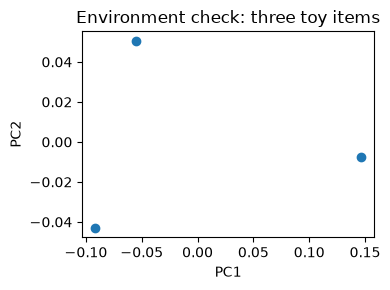

Local environment checks passed. Next, test loading your category.


In [ ]:
# 2. Check that the libraries can do a little work, not just import.
#Create check ratings DataFrame
check_ratings = pd.DataFrame(
    [("A", "X", 5), ("A", "Y", 2), ("B", "X", 4),
     ("B", "Z", 3), ("C", "Y", 4), ("C", "Z", 1)],
    columns=["user", "item", "rating"]
)
#surprise dataset, a requirement for the models to work with rating scale
check_train = Dataset.load_from_df(check_ratings, Reader(rating_scale=(1, 5))).build_full_trainset()

for check_model in [
    KNNBasic(k=2, sim_options={"name": "cosine", "user_based": False}, verbose=False), #k neightbors, cosine similarity, item-based
    KNNWithMeans(k=2, sim_options={"name": "pearson", "user_based": True}, verbose=False), #k neightbors, pearson similarity, user-based
    SVD(n_factors=2, n_epochs=3, random_state=SEED), #Singular Value Decomposition, n_factors: learned latent factors, n_epochs: number of iterations
]:
    check_model.fit(check_train) # Fit the model on the training data(surprise dataset)
    check_prediction = check_model.predict("A", "Z").est # Predict the rating for user "A" and item "Z"
    assert np.isfinite(check_prediction) # Check that the prediction is a finite number
    print(f"{type(check_model).__name__}: predicted rating = {check_prediction:.3f}")

# The last model above is SVD. Test PCA and plotting with its three item vectors.
check_points = PCA(n_components=2).fit_transform(check_model.qi) #.qi is the item factors learned by SVD. PCA reduces the dimensionality of these factors to 2D for visualization.
assert check_points.shape == (3, 2) and np.isfinite(check_points).all()
plt.figure(figsize=(4, 3))
plt.scatter(check_points[:, 0], check_points[:, 1])
plt.title("Environment check: three toy items")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

print("Local environment checks passed. Next, test loading your category.")

warnings.filterwarnings("ignore")
# Reset the seed so the check does not change later experiments.
random.seed(SEED); np.random.seed(SEED)
#PCA works with SVD.PCA is a dimensionality reduction technique that can be applied to the item vectors learned by SVD to visualize them in a lower-dimensional space.

**Each model has different assumptions and methods for predicting ratings. 

KNNBasic uses the k-nearest neighbors algorithm with cosine similarity to find similar items and predict ratings based on those similarities. equally rated weighted rating from similar items 1 rater

KNNWithMeans also uses k-nearest neighbors but incorporates the mean rating of users to adjust predictions, using Pearson correlation for similarity. fall back to mean of user A, since no usable neighbor(not identaically similar)

SVD (Singular Value Decomposition) is a matrix factorization technique that learns latent factors representing users and items, allowing it to predict ratings based on these learned representations. learned numerical factors and rating adjustments
\[
\hat r_{AZ}=\mu+b_A+b_Z+p_A^\top q_Z
\]
Term	Mathematical meaning
\(\mu\)	Average of all training ratings
\(b_A\)	Adjustment for A's general rating tendency
\(b_Z\)	Adjustment for Z's rating tendency
\(p_A\)	Vector representing A's learned preferences
\(q_Z\)	Vector representing Z's learned characteristics
\(p_A^\top q_Z\)	Dot product measuring compatibility between A and Z
then, SVD starts from the overall average and uses learned user/item information to adjust its prediction. the model learned those numbers during training**


## 0. Load your assigned dataset (given)

Download the ZIP assigned by the instructor from Moodle. Extract its category folder beside this
notebook. For example, `Video_Games/ratings.csv` and `Video_Games/items.csv` should be beside
`Recommender_LAB_student.ipynb`. On JupyterHub, upload the ZIP and extract it on the server.

Read `dataset_info.md` in that folder. Set `CATEGORY` below to the folder name exactly.
Use these prepared files without downloading raw Amazon data, sampling again or applying 5-core
again. The data are not yet split into training and validation sets.

In [ ]:
from pathlib import Path
#get the data
CATEGORY = "Automotive"  # Your assigned category, e.g. "Video_Games".
DATA_DIR = Path(CATEGORY)

if not (DATA_DIR / "ratings.csv").is_file():
    raise FileNotFoundError(f"Extract your assigned ZIP beside this notebook and check CATEGORY: {DATA_DIR}")
#read items and ratings
ratings = pd.read_csv(DATA_DIR / "ratings.csv",
                      dtype={"user": "string", "item": "string", "time": "int64"})
items = pd.read_csv(DATA_DIR / "items.csv", dtype={"item": "string", "item_title": "string"})
# Keep every rating, including ratings for items whose title is missing. MERGE
df = ratings.merge(items[["item", "item_title"]], on="item", how="left", validate="many_to_one")
assert len(df) == len(ratings) and not df.duplicated(["user", "item"]).any()

# Timestamps are already Unix seconds. Do not divide them by 1,000. STATS
n_users, n_items = df.user.nunique(), df.item.nunique() # Count unique users and items
density = len(df) / (n_users * n_items) # Calculate the density of the user-item matrix
print(f"[prepared data] ratings={len(df):,}  users={n_users:,}  items={n_items:,}  density={density:.2%}")
print(f"Items with titles: {df.dropna(subset=['item_title']).item.nunique():,}/{n_items:,}")


[prepared data] ratings=10,617  users=1,513  items=972  density=0.72%
Items with titles: 972/972


### What preprocessing has already been done?

The instructor started from published, deduplicated 5-core ratings. Within each category, the
recipe selected up to 1,500 of the most-rated items and up to 2,000 users with at least 5 ratings
among those items (seed 42). It kept those users' ratings within that catalogue, removed repeated
user-item pairs and applied 5-core again.

**5-core:** each user has rated at least 5 distinct items, and each item has ratings from at least
5 distinct users. Removing users can reduce item counts, and removing items can reduce user counts,
so filtering repeats until both conditions hold. This describes the supplied dataset before
the validation split.

The subset favours popular items and users active within that catalogue. It is not a random sample
of Amazon. Explain this limitation in your analysis. Missing titles do not mean missing ratings:
keep those rows for modelling, and use titled items for the neighbour-inspection examples.

## Task 1 — Explore the dataset and trivial baselines
**Your turn.** (a) Two EDA figures: the rating histogram and the item-popularity distribution on a
log–log scale. (b) RMSE baselines: global mean, user mean, item mean. (c) A top-K popularity
recommender.

> **CHECKPOINT — Week 2:** Show Task 1 during the short progress check: statistics, both EDA figures,
> the RMSE-baseline table and popularity results. Checks begin in session 1 and may continue in
> the consecutive session 2.

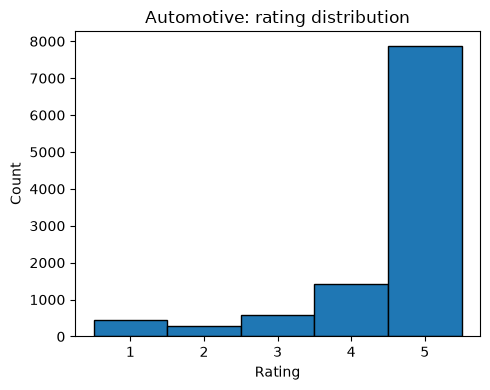

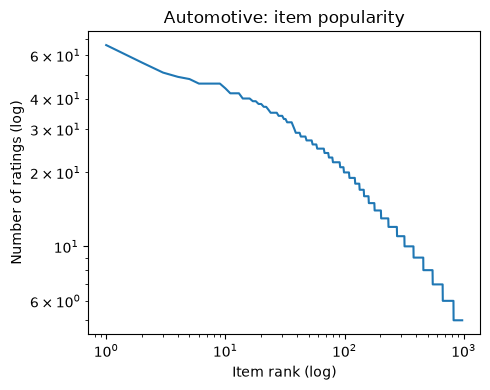

In [6]:
# TODO(you) — Task 1a: two EDA figures.
#  1) histogram of df["rating"] (bins centered on 1..5)
#  2) item popularity: counts = df["item"].value_counts(); plot rank vs count with plt.loglog(...)
# In the Task 1 interpretation cell, describe the item-popularity distribution in one sentence.

# 1) Rating histogram
plt.figure(figsize=(5, 4))
plt.hist(df["rating"], bins=np.arange(0.5, 6.5, 1), edgecolor="black")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.title(f"{CATEGORY}: rating distribution")
plt.tight_layout()
plt.show()

# 2) Item popularity, log-log rank vs count
item_counts = df["item"].value_counts()
ranks = np.arange(1, len(item_counts) + 1)
plt.figure(figsize=(5, 4))
plt.loglog(ranks, item_counts.values)
plt.xlabel("Item rank (log)")
plt.ylabel("Number of ratings (log)")
plt.title(f"{CATEGORY}: item popularity")
plt.tight_layout()
plt.show()

In [ ]:
#training and validation split
#Temporal means based on time.
#Leave-last-one-out means remove the latest interaction of each user from training.
#Split means divide the dataset into separate parts.

#-------------------------DATA PREPARATION

# --- Temporal leave-last-one-out split (given): per user, the LATEST interaction is validation.
def leave_one_out_by_time(df):
    # Stable sort makes equal-timestamp ties deterministic. Index selection preserves legitimate
    # duplicate-valued rows; concat(...).drop_duplicates(keep=False) would silently delete them.
    df_sorted = df.sort_values(["user", "time"], kind="mergesort").reset_index(drop=True) #sort rating by user and time
    validation_idx = df_sorted.groupby("user", sort=False).tail(1).index #identified the index of the last rating for each user
    validation = df_sorted.loc[validation_idx] #get the last rating for each user as validation data
    train = df_sorted.drop(index=validation_idx) #create the training data by dropping the validation indices
    return train.reset_index(drop=True), validation.reset_index(drop=True) 

train_df, validation_df = leave_one_out_by_time(df)
print(f"[split] train rows={len(train_df):,}  validation users={len(validation_df):,}")
# Be ready to explain why the split uses each user's latest interaction rather than a random one.

[split] train rows=9,104  validation users=1,513


In [ ]:
# TODO(you) — Task 1b: RMSE baselines on the split above. How accurately can we predict ratings using only simple averages?
#how far our predicted ratings are from the actual ratings, with larger errors receiving a stronger penalty.



def baselines_rmse(train_df, validation_df):
    """Return {"GlobalMean_RMSE": .., "UserMean_RMSE": .., "ItemMean_RMSE": ..}.
    Predict every validation rating with (a) the global train mean, (b) that user's train mean
    (fall back to global for unseen users), (c) that item's train mean (same fallback)."""
    global_mean = train_df["rating"].mean() #Global mean	Predict the same overall average for every user and item
    user_mean = train_df.groupby("user")["rating"].mean()#User mean	Predict using the particular user's average rating
    item_mean = train_df.groupby("item")["rating"].mean()#Item mean	Predict using the particular item's average rating

    actual = validation_df["rating"].to_numpy() #list of actual ratings in the validation set

    def rmse(preds):
        preds = np.asarray(preds, dtype=float) #convert the predictions to a numpy array of floats
        return float(np.sqrt(np.mean((preds - actual) ** 2)))

    global_preds = np.full(len(validation_df), global_mean) #we predict the same overall average for every user and item
    user_preds = validation_df["user"].map(user_mean).fillna(global_mean).to_numpy()
    item_preds = validation_df["item"].map(item_mean).fillna(global_mean).to_numpy()

    return {
        "GlobalMean_RMSE": rmse(global_preds),
        "UserMean_RMSE": rmse(user_preds),
        "ItemMean_RMSE": rmse(item_preds),
    }

base_rmse = baselines_rmse(train_df, validation_df)
print(base_rmse)
#equation of the RMSE is sqrt(mean((preds - actual) ** 2)), mean 1/n sigma

{'GlobalMean_RMSE': 1.143272804426186, 'UserMean_RMSE': 1.1138765550793936, 'ItemMean_RMSE': 1.1858592863567405}


### Choose the items each model will rank (given)

For each user, we hid their latest interaction in the validation set. Its item is the **target item**.
The **candidate items** are the target and other items the user has not rated in the training data.
These other items are not known dislikes.

To keep evaluation fast, use at most **2,000 users** and **200 candidate items per user**.
The 200 includes the target. Choose these lists once, using a fixed random seed, and reuse them
for every model. The split already gives us one validation row per user.

In [ ]:
MAX_RANK_USERS = 2000
RANK_CANDIDATE_CAP = 200
#select the validation users for ranking evaluation. If there are more than MAX_RANK_USERS, randomly sample that many.
rank_validation_df = validation_df
if len(rank_validation_df) > MAX_RANK_USERS:
    rank_validation_df = rank_validation_df.sample(MAX_RANK_USERS, random_state=SEED)
rank_validation_df = rank_validation_df.sort_values('user')

items_all = sorted(train_df['item'].unique()) # List of all items sorted in ascending order. This will be used to generate candidate items for ranking evaluation.
seen_by_user = {}
for user, user_ratings in train_df.groupby('user'):
    seen_by_user[user] = set(user_ratings['item'])
    #prepare data for recommendation
    #users and items are the unique users and items in the training data. The seen_by_user dictionary maps each user to a set of items they have rated in the training data. This will be useful for generating candidate items for ranking evaluation, as we want to recommend items that the user has not already seen.
    #rank each user's predictions

In [ ]:
#we prepared:
#items_all: all unique items in training.
#seen_by_user: items each user has already rated.
#rank_validation_df: the validation users and their held-out items.
# we need these to create list that each user can recieve as recommendations, which will be used to evaluate the ranking performance of our recommendation models.

rng = np.random.default_rng(SEED) #Random-number generator with a fixed seed
candidate_items_by_user = {} #Stores possible recommendation items for each user
target_item_by_user = {} #Stores each user's actual held-out validation item

# Each row contains one user and their hidden item. | through validation_df, we can get the user and their corresponding target item. We will then generate a list of candidate items for each user, which will be used to evaluate the ranking performance of our recommendation models.
for user, target_item in rank_validation_df[['user', 'item']].itertuples(index=False, name=None): #each row as pair of user and target item
    seen_items = seen_by_user[user] #user already rated items
    candidates = [item for item in items_all if item not in seen_items] #Go through every available item and keep only those that the current user hasn't rated in training.

    # A target absent from training cannot be retrieved from the training catalogue.
    if target_item not in candidates:
        continue

    if len(candidates) > RANK_CANDIDATE_CAP:
        other_items = [item for item in candidates if item != target_item]
        candidates = rng.choice(other_items, size=RANK_CANDIDATE_CAP - 1, replace=False).tolist()
        candidates.append(target_item)

    candidate_items_by_user[user] = candidates
    target_item_by_user[user] = target_item

assert target_item_by_user, 'No users have an eligible target item for ranking.'
print('Users evaluated:', len(target_item_by_user))
print('Users excluded:', len(rank_validation_df) - len(target_item_by_user))
print('Maximum candidate items per user:', RANK_CANDIDATE_CAP)

Users evaluated: 1513
Users excluded: 0
Maximum candidate items per user: 200


### Task 1c - Rank by popularity

Count each item's ratings in **training data only**. For each user, rank their candidate items
by this count and keep the first 10 (or all candidates if there are fewer than 10).
When counts are tied, sort by item ID so the result is repeatable.

Store the lists in `popularity_recommendations`, with one entry for every user in
`candidate_items_by_user`. For example, an entry could look like
`popularity_recommendations["user_A"] = ["item_C", "item_B", "item_F"]`.
Use the real user and item IDs from your data.

In [ ]:
# TODO(you) — Task 1c: non-personalized popularity recommender.
# 1. Count training ratings per item; train_df['item'].value_counts() can help.
# 2. Loop over: for user, candidates in candidate_items_by_user.items():
# 3. Rank only those candidates by count (highest first), then item ID for ties.
# 4. Store the first 10 item IDs in popularity_recommendations[user].
popularity_recommendations = {} #Recommend the most popular items that each user hasn't already rated in training.

item_counts = train_df['item'].value_counts()

for user, candidates in candidate_items_by_user.items():
    ranked_candidates = sorted(
        candidates,
        key=lambda item: (-item_counts.get(item, 0), item)
    )
    popularity_recommendations[user] = ranked_candidates[:10]

### Inspect one user's recommendations (given)

Run this after completing Task 1c. Compare the hidden item with your top-10 list.
Change `EXAMPLE_ROW` to inspect another user. Only users with an eligible target are listed.

In [ ]:
#inspection eg. for one user
EXAMPLE_ROW = 0 #select the first user in the list of users with target items for ranking evaluation.
ranking_users = list(target_item_by_user)
example_user = ranking_users[EXAMPLE_ROW]

target_item = target_item_by_user[example_user] #the product whose ratings were hidden for the user in the validation set. This is the item we want to see if our recommendation model can successfully recommend to the user.
candidates = candidate_items_by_user[example_user] #the items that are candidates for recommendation to the user up to 200 eligible items
recommended_items = popularity_recommendations[example_user] #the top 10 items recommended to the user by the popularity recommender

item_titles = items.set_index('item')['item_title'] #find product titles for the items in the recommendations. This will be used to display the titles of the recommended items in the output.

print('User:', example_user)
print('Hidden item:', target_item, '-', item_titles.get(target_item, 'title unavailable'))
print('Number of candidate items:', len(candidates))
print('First five candidate items:', candidates[:5])
print('Hidden item is included among the candidates:', target_item in candidates) #to check if the hidden item is included in the candidate items for the user

example_recommendations = pd.DataFrame({'item': recommended_items})
example_recommendations.insert(0, 'position', range(1, len(recommended_items) + 1))
example_recommendations['title'] = example_recommendations['item'].map(item_titles).fillna('title unavailable')
example_recommendations['is hidden item'] = example_recommendations['item'] == target_item
display(example_recommendations)
#the hidden product wasn't found in the results, which means the popularity recommender didn't recommend the hidden item to the user. This is expected, as the popularity recommender doesn't take into account the user's preferences or history, and simply recommends the most popular items overall.

User: AE26X3GVKQECDJDCV2H3CI5WMKNA
Hidden item: B07QKWJ6SQ - Camco 4-Inch RV Bumper Caps | Easy Removal | Durable Construction | Black, 2-pack (40303)
Number of candidate items: 200
First five candidate items: ['B086NHL4ZL', 'B0B5TG8M95', 'B0C3468DZN', 'B09BC4JFHL', 'B0C5VJT1B6']
Hidden item is included among the candidates: True


,position,item,title,is hidden item
0,1,B09XJWSS7H,Camco 45 Degree Hose Elbow- Eliminates Stress ...,False
1,2,B0BXF576XX,Mobil 1 High Mileage Full Synthetic Motor Oil ...,False
2,3,B001V8U12M,Camco RV Leveling Scissor Jack Socket Drill Ad...,False
3,4,B07FHPCC19,Battery Tender Ring Terminal Harness Accessory...,False
4,5,B0037V0EW8,TEKTON Digital Tire Gauge | 5941,False
5,6,B0C3468DZN,Meguiar's M10501 Mirror Glaze Ultra-Cut Compou...,False
6,7,B07YVP6NFK,STA-BIL Storage Fuel Stabilizer - Keeps Fuel F...,False
7,8,B0C62LCLJP,Meguiar's 3-in-1 Liquid Wax - 20 Oz Bottle,False
8,9,B01HTKX2W6,"Bosch 15726 Oxygen Sensor, Universal Fitment",False
9,10,B08WXKVKN1,"Meguiar's G210608EU Ultimate Paste Wax 227g, I...",False


A **hit** means that the hidden item appears in the top 10. NDCG also rewards placing it
near the top. Here there is exactly one target per user: its best possible position is 1,
giving a score of 1. If it is third, its score is $1 / \log_2(3 + 1) = 0.5$.
If it is missing from the top 10, both scores are zero.

In [ ]:
hit = 0
ndcg = 0.0
if target_item in recommended_items:
    hit = 1 #if hidden item is in the top 10 recommendations, hit is 1, otherwise 0
    position = recommended_items.index(target_item) + 1 #find the position of the hidden item in the recommended items list (1-based index)
    ndcg = 1 / math.log2(position + 1)
    print('Hidden item position:', position)
else:
    print('Hidden item is not in the top 10.')

print('Hit:', hit)
print('NDCG:', ndcg)
#Hit: Did our recommender include the user's hidden product in its top 10?
#NDCG: If it did, how high did the product appear in the ranking?

Hidden item is not in the top 10.
Hit: 0
NDCG: 0.0


### Calculate the three metrics across users (given)

- **HitRate@10:** the fraction of users whose hidden item appears in the top 10.
- **NDCG@10:** the average of the per-user scores calculated above.
- **Coverage@10:** the fraction of training-catalogue items recommended to at least one user.

All models use the same users and candidate items. An empty recommendation list counts as a miss;
it does not remove the user from the calculation. These scores describe retrieval of a held-out
review within our candidate lists, not purchases or user satisfaction.

The small check below catches recommendations that are too long, repeated, or outside the user's
candidate list. The evaluator returns overall scores and a table with one row per user.
We keep that table for the popularity-group comparison in Task 4; no predictions need to be repeated.

In [ ]:
def check_recommendations(user, recommended_items, K):
    assert len(recommended_items) <= K, 'Too many recommended items.'
    assert len(recommended_items) == len(set(recommended_items)), 'Repeated item in recommendations.'
    assert set(recommended_items).issubset(candidate_items_by_user[user]), 'Item outside candidate list.'
    #We recommended 10 products to each user.
    #We checked one user and found that their hidden product was not recommended.
    #We created a function to check whether recommendation lists are valid.

In [ ]:
# Evaluate the ranking performance of a recommender system using Hit Rate, NDCG, and Coverage metrics.
def evaluate_ranking(recommendations_by_user, K=10):
    rows = []
    recommended_catalog = set() # because if we recommend the same item to multiple users, we only want to count it once for coverage.

    for user, target_item in target_item_by_user.items(): #evaluate each user and their hidden item
        recommended_items = recommendations_by_user[user] # get the recommended/hidden items for the user, top K items, 
        check_recommendations(user, recommended_items, K) #check that the recommendations are valid for the user
        recommended_catalog.update(recommended_items) # add the recommended items to the catalog

        hit, ndcg = 0, 0.0
        if target_item in recommended_items: #if the hidden item is in the recommended items, we have a hit and we calculate the NDCG
            hit = 1
            position = recommended_items.index(target_item) + 1
            ndcg = 1 / math.log2(position + 1)
        rows.append({'user': user, 'item': target_item, 'hit': hit, 'ndcg': ndcg})

    # Use every eligible user, including users with an empty recommendation list. Calculate the average Hit Rate, NDCG, and Coverage across all users.
    details = pd.DataFrame(rows)
    scores = {'HitRate@K': details['hit'].mean(), 'NDCG@K': details['ndcg'].mean(),
              'Coverage@K': len(recommended_catalog) / len(items_all)}
    return scores, details
# Evaluate the popularity-based recommender
pop_scores, pop_details = evaluate_ranking(popularity_recommendations, K=10)
ranking_details = {'Popularity': pop_details}
display(pd.DataFrame([{'model': 'Popularity', **pop_scores}]))
#	The popularity recommender retrieves a minority of hidden items and recommends a limited portion of the catalogue

,model,HitRate@K,NDCG@K,Coverage@K
0,Popularity,0.115003,0.056653,0.099794


HitRate@10 = 11.50%

Out of 1,513 evaluated users, the hidden product appeared in the top 10 for 174 users.

That means the popularity recommender retrieved the hidden product for approximately 11.5% of users.

NDCG@10 = 0.0567

This is the average position-weighted score across all users.

It is low because most hidden products weren't in the top 10, and even successful recommendations may have appeared lower in the list.

Coverage@10 = 9.98%

Out of 972 products in the training catalogue, only 97 different products appeared in at least one user's top-10 recommendations.

This tells us that the popularity recommender concentrates its recommendations on a relatively small part of the available catalogue.

**Task 1 interpretation (2-3 sentences).** Describe the rating distribution and
the concentration of item popularity. State how selecting popular items and active users may limit this conclusion.

> ...
> • Rating distribution:
Ratings are heavily skewed toward the positive end — the large majority are 5 stars, with a much smaller amount at 4 stars, and 1-3 stars are all relatively rare (2 stars being the least common of all).

> • Item popularity concentration:
Item popularity is highly concentrated: the log-log rank-vs-count plot shows a small number of items receiving far more ratings than typical items, with the curve dropping off steeply after roughly the top 100-200 items, leaving a long tail of items with only a handful of ratings each.

> • Limitation from popular-items/active-users selection:
Because this dataset was built by keeping only the most-rated items and the most active users (5-core filtering), this concentration is partly an artifact of that selection — a random, unfiltered sample of all Amazon Automotive reviews would likely show an even longer, thinner tail of rarely-rated items and less-active users than what's visible here.
that affected the error reduction metholodologies used.


## Task 2 — Similarity-based collaborative filtering
**Your turn.** First reproduce the lecture comparison with raw-rating `KNNBasic`. Then use
`KNNWithMeans` for the user/item × cosine/Pearson comparison. Compare RMSE and ranking metrics,
and inspect nearest neighbors of 3 popular items with available titles. What changes when ratings are
mean-centered, and what is the role of neighborhood size `k`?

Use `k=40` for the five main configurations. Then rerun one mean-centered
configuration with `k=10`, keeping the other settings unchanged. Include both rows in your
comparison and describe what changed. No larger kNN grid is required.

**The given evaluator:** `fit_and_evaluate_surprise` fits one model on `train_df` and computes
RMSE using all validation ratings. For ranking, it predicts a rating for each candidate item and
keeps the top 10. It stores these lists in the same form as `popularity_recommendations`, then
uses `evaluate_ranking` again. All models use the same selected users and candidate items.
It returns two values: `scores, details`. Save the per-user table as
`ranking_details[name] = details`, using the same model name as in your results table.

In [ ]:
from surprise import Dataset, Reader, KNNBasic, KNNWithMeans, SVD, accuracy

#user with similar rating pattern or product rated similarly by users
def fit_and_evaluate_surprise(model, train_df, validation_df, K=10): #prepare the data for the surprise library, fit the model, and evaluate its performance on the validation set.
    reader = Reader(rating_scale=(1, 5))
    training_data = Dataset.load_from_df(train_df[['user', 'item', 'rating']], reader)
    model.fit(training_data.build_full_trainset()) # Fit the model on the training data (surprise dataset)

    # Rating prediction: compare predicted and actual validation ratings. RMSE, same as 1B
    predictions = []
    for user, item, rating in validation_df[['user', 'item', 'rating']].itertuples(index=False, name=None):
        predictions.append(model.predict(user, item, r_ui=rating))
    rmse = accuracy.rmse(predictions, verbose=False)

    # Ranking: score the same candidate lists used by popularity. Recommendation ranking is based on the predicted ratings for each candidate item for each user. The top K items with the highest predicted ratings are recommended to the user.
    recommendations_by_user = {}
    for user, candidates in candidate_items_by_user.items():
        predicted_ratings = [model.predict(user, item).est for item in candidates]
        scores = pd.DataFrame({'item': candidates, 'score': predicted_ratings})
        scores = scores.sort_values(['score', 'item'], ascending=[False, True])
        recommendations_by_user[user] = scores['item'].head(K).tolist()
# similar to 1C, we evaluate the ranking performance of the recommender system using Hit Rate, NDCG, and Coverage metrics. We also include the RMSE score in the results.
    results, details = evaluate_ranking(recommendations_by_user, K)
    results['RMSE'] = rmse
    return results, details

In [ ]:
# TODO(you) — Task 2a: one raw comparison + four mean-centered kNN variants. #we run 6 kNN models with different configurations and evaluate their performance on the validation set. We store the results in a DataFrame for comparison.
knn_configs = {
    "Raw item-kNN (cosine)": KNNBasic(
        k=40, sim_options={"name": "cosine", "user_based": False}, verbose=False),
    "Mean-centered item-kNN (cosine)": KNNWithMeans(
        k=40, sim_options={"name": "cosine", "user_based": False}, verbose=False),
    "Mean-centered item-kNN (pearson)": KNNWithMeans(
        k=40, sim_options={"name": "pearson", "user_based": False}, verbose=False),
    "Mean-centered user-kNN (cosine)": KNNWithMeans(
        k=40, sim_options={"name": "cosine", "user_based": True}, verbose=False),
    "Mean-centered user-kNN (pearson)": KNNWithMeans(
        k=40, sim_options={"name": "pearson", "user_based": True}, verbose=False),
}
#run the models and collect results
rows = []
knn_models = {}
for name, algo in knn_configs.items():
    scores, details = fit_and_evaluate_surprise(algo, train_df, validation_df)
    ranking_details[name] = details
    knn_models[name] = algo
    rows.append({"model": name, **scores})

# Extra required run: one mean-centered config rerun with k=10 (others unchanged).
extra_name = "Mean-centered item-kNN (cosine), k=10"
extra_algo = KNNWithMeans(k=10, sim_options={"name": "cosine", "user_based": False}, verbose=False) #additional model with k=10 for comparison
scores, details = fit_and_evaluate_surprise(extra_algo, train_df, validation_df)
ranking_details[extra_name] = details
knn_models[extra_name] = extra_algo
rows.append({"model": extra_name, **scores})

knn_results = pd.DataFrame(rows)
display(knn_results)

,model,HitRate@K,NDCG@K,Coverage@K,RMSE
0,Raw item-kNN (cosine),0.071381,0.030759,0.842593,1.229121
1,Mean-centered item-kNN (cosine),0.040317,0.018093,0.354938,1.235986
2,Mean-centered item-kNN (pearson),0.041639,0.018930,0.165638,1.188147
3,Mean-centered user-kNN (cosine),0.056180,0.023667,0.880658,1.161336
4,Mean-centered user-kNN (pearson),0.046266,0.020118,0.394033,1.115194
5,"Mean-centered item-kNN (cosine), k=10",0.040317,0.018093,0.354938,1.235918


RESULTS

For rating prediction (RMSE): Mean-centered user-KNN with Pearson is the best of the six, with RMSE 1.1152.

For finding hidden products (HitRate): Raw item-KNN with cosine is the best KNN configuration here, retrieving the hidden product for 7.14% of users.

For product variety (Coverage): Mean-centered user-KNN with cosine recommends the broadest variety of products, covering 88.07% of the training catalogue.

These are different winners because predicting ratings accurately is not the same thing as retrieving hidden products in the top 10.

Changing k from 40 to 10 made almost no difference to RMSE, and the ranking metrics remained identical.

That means increasing the maximum number of neighbors did not improve this configuration's measured performance. We cannot conclude exactly why from this table alone.

User-KNN

Find similar users

If users A and B have similar rating patterns, we can use B's ratings to help predict what A might like.



Item-KNN

Find similar products

If products X and Y received similar rating patterns, we can use a user's rating of X to help predict their rating of Y.



Cosine / Pearson

Two ways to measure similarity

Cosine measures how aligned the observed rating vectors are. Pearson compares how ratings vary relative to their averages.



k

Maximum number of neighbors used

k=40 means the model can use up to 40 similar users or products when making a prediction. If fewer useful neighbors exist, it may use fewer.

A mean-centered prediction method takes those different rating habits into account. Rather than simply combining raw neighbor ratings, it combines how much those ratings differ from each neighbor's average, then adjusts for the target user's or item's average.

That is the key difference between KNNBasic and KNNWithMeans here.


Previous method	Best relevant result

Task 1B: User-average baseline	RMSE = 1.1139

Task 2A: Best KNN	RMSE = 1.1152

Task 1C: Popularity recommender	HitRate@10 = 11.50%

Task 2A: Best KNN ranking	HitRate@10 = 7.14%


Notice something interesting: None of these KNN models beats the simple user-average baseline on RMSE, or the popularity recommender on HitRate@10.

That doesn't mean KNN is useless. It means that on this particular dataset, with this split and these settings, more complicated models have not yet demonstrated an improvement on those metrics.

And that is exactly why we are comparing models rather than assuming more sophisticated algorithms must work better.

The central idea of Task 2A: We're not simply testing whether KNN works. We're investigating how choosing the neighbors, measuring similarity, and adjusting for average ratings affects its predictions and recommendations.

In [ ]:
# TODO(you) — Task 2b: nearest neighbors of 3 popular items, WITH TITLES. Find the most similar products to three popular items according to the rating pattern learned by KNN, which 5 products are most similar to that charger
titles_map = (df.dropna(subset=["item_title"]).drop_duplicates("item") #ID to title mapping. 
                .set_index("item")["item_title"].to_dict())

def neighbors_with_titles(algo_item_knn, item_asin, k=5): #function to find neighborhood
    """Return [(neighbor_asin, title), ...] for the k nearest neighbors of item_asin
    under a FITTED item-based KNNBasic or KNNWithMeans model.
    Hints (Surprise ID conversion): inner = algo.trainset.to_inner_iid(item_asin)
                                  nbrs  = algo.get_neighbors(inner, k=k)
                                  raw   = algo.trainset.to_raw_iid(inner_neighbor)"""
    inner = algo_item_knn.trainset.to_inner_iid(item_asin) #convert the raw item ID to the inner ID used by the Surprise library
    inner_neighbors = algo_item_knn.get_neighbors(inner, k=k) #get the inner IDs of the k nearest neighbors of the item
    result = []
    for inner_neighbor in inner_neighbors: #convert the inner ID of the neighbor back to the raw item ID and get its title from the titles_map. If the title is not available, use "title unavailable" as a placeholder.
        raw = algo_item_knn.trainset.to_raw_iid(inner_neighbor) #convert the inner ID of the neighbor back to the raw item ID
        title = titles_map.get(raw, "title unavailable") #get the title of the neighbor item from the titles_map, or use "title unavailable" if the title is not available
        result.append((raw, title))
    return result

# Pick 3 popular TRAINING items with titles from YOUR category and print their neighbors. select the most 3 popular in the training set that have titles, then find their 5 nearest neighbors using the fitted item-based KNN model. Print the item IDs and titles of the neighbors for each popular item.
popular_titled_items = (
    train_df[train_df["item"].isin(titles_map)]["item"] 
    .value_counts().head(3).index.tolist()
)

item_knn_model = knn_models["Mean-centered item-kNN (cosine)"]  # any FITTED item-based model

for item_id in popular_titled_items:
    print("Item:", titles_map.get(item_id, item_id))
    for neighbor_id, neighbor_title in neighbors_with_titles(item_knn_model, item_id, k=5):
        print("   →", neighbor_title, f"({neighbor_id})")
    print()

Item: Battery Tender 021-0123 Junior 12V, 0.75A Battery Charger and Maintainer, Black/Green (021-0123)
   → Camco - 45195-A RV Vent Insulator And Skylight Cover Without Reflective Surface, Fits Standard 14" RV Vents - 45195 (B00IUGO2HS)
   → LED License Plate Light for Trailer [Bracket Mount] [DOT FMVSS 108] [SAE L] [Black-Finish] [Waterproof] [12V DC] License Tag Lights for UTV ATV Trailer Truck RV Boat (B0842ZJCFN)
   → Permatex 09980 Counterman's Choice Spark Plug Boot and Electrical Connector Dielectric Grease, 4 g pouch (B08MJT7K95)
   → FIAMM 72112 Freeway Blaster LOW Note Horn (B000DINKPQ)
   → Roam Bike Phone Mount - Motorcycle Phone Mount- 360° Rotation with Universal Handlebar Fit for Bikes, Motorcycles, Scooters, Strollers - Phone Holder For Bike Compatible w/iPhone & Android Cell Phones (B01LWDCSIZ)

Item: Camco TastePURE Camper/RV Water Filter & Hose Protector | Inline Water Filter Reduces Bad Taste, Odor, Chlorine & Sediment | Ideal for RVs, Campers, Travel Trailers, Boat

Look at the third product: an RV drinking water hose.

Its nearest neighbors include car wax, bumper clips, polishing compound, octane booster, and chain lubricant.

Are these products functionally similar to a drinking water hose?

Not really.

So why does KNN consider them similar?

Because KNN isn't reading their names or understanding their purpose.

It is looking at rating patterns.

Two products might be considered similar because overlapping users rated them in similar ways, even if the products serve completely different purposes.

And remember Task 1A: our Automotive dataset is very sparse, with only 0.72% of possible user–item ratings observed.

With limited shared ratings, similarity estimates can be unreliable.

Some neighbor pairs make reasonable sense within the broad RV category, such as an RV water filter and RV shower head. Others appear functionally unrelated.

This is evidence that the learned similarities don't consistently match product functionality. We cannot establish the exact cause of each pairing without inspecting the underlying shared ratings and similarity scores.

Main conclusion: Task 2A measured how well KNN performs numerically. Task 2B helps us understand what the model considers similar and whether those relationships are credible.

**Task 2 interpretation (3-5 sentences).** Compare raw and mean-centered kNN,
identify the strongest configuration, and explain whether the nearest neighbors are credible.

> ...
> Comparing the five k=40 configurations, raw item-kNN (cosine) had the best ranking performance of the kNN variants (HitRate@10=0.071, NDCG@10=0.031), but every kNN configuration still ranked below the popularity baseline (HitRate@10=0.115). Mean-centering consistently hurt ranking performance here (e.g. mean-centered item-kNN cosine dropped to HitRate@10=0.040), likely because ratings are so skewed toward 5 stars that subtracting user/item means removes more useful signal than noise. Mean-centered user-kNN (pearson) achieved the best RMSE (1.115), essentially matching the UserMean baseline, since it is effectively a refined version of that same idea. Rerunning mean-centered item-kNN (cosine) with k=10 instead of k=40 produced almost identical scores, suggesting that with only ~9 ratings per item on average, most items don't have enough co-rated neighbors for a larger k to matter — the usable neighborhood is already limited by data sparsity, not by the k setting. The nearest-neighbor inspection in Task 2b supports this: neighbors of a battery charger, a water filter, and a water hose were mostly unrelated products (e.g. bike phone mounts, wax, octane booster), suggesting the model is picking up on co-occurrence among generally popular items rather than genuine product similarity — a known failure mode of item-based kNN on sparse data. Coverage told a different story: several kNN variants (up to 0.88) recommended a far wider slice of the catalog than popularity (0.10), showing that even though kNN ranked worse, it spread recommendations across many more items instead of repeatedly surfacing the same best-sellers.
>
> Some neighbor pairs show plausible RV/automotive-accessory relatedness (e.g. the water filter's neighbors included an RV vent insulator and an RV shower head), but most neighbors across all three inspected items look unrelated to the source item's actual function. This is consistent with sparse-data item-kNN picking up shared popularity rather than true similarity — items like Meguiar's wax products appear repeatedly as "neighbors" of very different products, likely because they were rated by a broad, overlapping set of users rather than because they're functionally similar.
> 

## Task 3 — Matrix factorization
**Your turn.** Train plain `SVD` over a small grid of **six** settings, varying `n_factors`
and `reg_all`. For example, use factor counts `[10, 30, 50]` and penalties `[0.02, 0.1]`.
Keep `n_epochs=20` and the random seed fixed. Compare the validation results with Task 2.

`SVD` learns a rating model: `global mean + user bias + item bias + user/item dot product`.
It uses SGD on observed ratings. It does not run classical SVD on a zero-filled rating matrix.

| Setting | Meaning |
|---|---|
| `n_factors` | Number of values in each user/item vector |
| `reg_all` | Penalty strength for large biases and factors |
| `lr_all` | Size of the learning steps; leave the default for this lab |
| `n_epochs` | Number of passes through training ratings |

More factors need not improve validation scores. State which metric guides your choice.

Do the same as KNN (Predict how a user might rate a product they haven not rated before.). but it learns a small numerical profile for every user and every product, then uses those profiles to predict ratings.

In [22]:
# TODO(you) — Task 3: MF models + a small hyperparameter grid.
# Suggested shape: for each (n_factors, reg_all) in a grid of 6 combinations:
#     algo = SVD(n_factors=..., reg_all=..., n_epochs=20, random_state=SEED)
#     scores, details = fit_and_evaluate_surprise(algo, train_df, validation_df)
#     ranking_details[name] = details
#     scores["n_factors"] = n_factors
#     scores["reg_all"] = reg_all
#     append {"model": name, **scores} to rows and store the fitted algo in mf_models[name]
# mf_results = pd.DataFrame(rows)
mf_results = None
mf_models = {}
# TODO(you)
# TODO(you) — Task 3: MF models + a small hyperparameter grid.
rows = []
mf_models = {}
for n_factors in [10, 30, 50]:
    for reg_all in [0.02, 0.1]:
        name = f"SVD(n_factors={n_factors}, reg_all={reg_all})"
        algo = SVD(n_factors=n_factors, reg_all=reg_all, n_epochs=20, random_state=SEED)
        scores, details = fit_and_evaluate_surprise(algo, train_df, validation_df)
        ranking_details[name] = details
        scores["n_factors"] = n_factors
        scores["reg_all"] = reg_all
        rows.append({"model": name, **scores})
        mf_models[name] = algo

mf_results = pd.DataFrame(rows)
display(mf_results)

,model,HitRate@K,NDCG@K,Coverage@K,RMSE,n_factors,reg_all
0,"SVD(n_factors=10, reg_all=0.02)",0.062789,0.028081,0.243827,1.094590,10,0.02
1,"SVD(n_factors=10, reg_all=0.1)",0.054197,0.024582,0.221193,1.094081,10,0.10
2,"SVD(n_factors=30, reg_all=0.02)",0.058824,0.028656,0.365226,1.093883,30,0.02
3,"SVD(n_factors=30, reg_all=0.1)",0.057502,0.026388,0.343621,1.093275,30,0.10
4,"SVD(n_factors=50, reg_all=0.02)",0.054858,0.026046,0.438272,1.094416,50,0.02
5,"SVD(n_factors=50, reg_all=0.1)",0.053536,0.025190,0.407407,1.093811,50,0.10


In [ ]:
#The best SVD RMSE was approximately 1.0933, compared with 1.1152 for the best KNN model. Lower is better, so this is an improvement.
#Second: More factors didn't automatically improve RMSE.
#Third: SVD did not beat our popularity recommender at retrieving hidden products. The best SVD HitRate was 6.28%, while Task 1C's popularity recommender achieved 11.50%.
#Argument	Meaning
#n_factors=n_factors	Use the factor count selected by the outer loop
#reg_all=reg_all	Use the regularization selected by the inner loop
#n_epochs=20	Train for 20 passes through the training ratings
#random_state=SEED	Make the random initialization reproducible

**Task 3 interpretation (3-5 sentences).** State which hyperparameters you tested,
which setting you selected, and whether SVD improved the metrics that matter for your objective.

> ...
> when testing six SVD configurations varied by n_factors (10, 30, 50) and reg_all (0.02, 0.1), keeping n_epochs=20 fixed. RMSE was nearly identical across all six (1.093-1.095), so more factors didn't meaningfully improve rating-prediction accuracy on this sparse dataset. Based on HitRate@10, I selected n_factors=10, reg_all=0.02 (HitRate@10=0.063), the best-ranking and smallest model in the grid. Compared to Task 2, SVD improved RMSE (its best, ~1.093, beat kNN's best of 1.115), but it did not improve ranking accuracy — its best HitRate@10 (0.063) was still lower than raw item-kNN's (0.071), and both remained below the Popularity baseline (0.115).

### Task 3b - Inspect one fitted prediction
Select one **plain SVD** model from your grid. Use a training pair so both IDs are known.
The helper below retrieves its learned parameters. Complete the prediction formula and compare
your answer with the library's **unclipped** prediction. This is a model-understanding check,
not a validation result.

`predict` normally clips scores to the 1-5 scale. `clip=False` lets us check the formula directly.

In [ ]:
# --- Parameter extraction (given).
def prediction_parts(fitted_svd, raw_user, raw_item):
    """Return mean, user bias, item bias, user factors and item factors for plain SVD."""
    if type(fitted_svd) is not SVD or not fitted_svd.biased: #check that the fitted model is a plain SVD model with biases enabled
        raise ValueError("Choose a plain SVD model with its default biases enabled.")
    ts = fitted_svd.trainset #access the training set used to fit the SVD model
    u = ts.to_inner_uid(raw_user) #convert the raw user ID to the inner ID used by the Surprise library
    i = ts.to_inner_iid(raw_item) #convert the raw item ID to the inner ID used by the Surprise library
    return ts.global_mean, fitted_svd.bu[u], fitted_svd.bi[i], fitted_svd.pu[u], fitted_svd.qi[i] #return the global mean rating, user bias, item bias, user factors, and item factors for the specified user and item. These values can be used to understand how the SVD model makes predictions for a given user-item pair.

Symbol	Meaning
\(\mu\)	Global average rating
\(b_u\)	User bias
\(b_i\)	Item bias
\(p_u\)	User factor vector
\(q_i\)	Item factor vector

In [ ]:
# TODO(you) - Task 3b: reconstruct one prediction.
svd_name = "SVD(n_factors=10, reg_all=0.02)"  # pick any of your 6 model names exactly as they appear above
svd_model = mf_models[svd_name] #get the fitted SVD model corresponding to the selected name
raw_user, raw_item = train_df[["user", "item"]].iloc[0] #select the first user-item pair from the training data for which we want to reconstruct the prediction
mu, bu, bi, p, q = prediction_parts(svd_model, raw_user, raw_item) #extract the components needed for the prediction
print("mean, user bias, item bias:", mu, bu, bi)
print("user factors:", p)
print("item factors:", q)

prediction = mu + bu + bi + np.dot(p, q) #calculate prediction manually
library_prediction = svd_model.predict(raw_user, raw_item, clip=False).est #calculate prediction using the fitted SVD model's predict method(surprise library)
print("Your prediction:", prediction, "Library prediction:", library_prediction)
assert np.isclose(prediction, library_prediction)
#so the calculations match the library's prediction, confirming that we have correctly reconstructed the prediction using the components extracted from the fitted SVD model.
#and we understand how the SVD model makes predictions for a given user-item pair by combining the global mean, user bias, item bias, and the dot product of the user and item latent factors.

mean, user bias, item bias: 4.5204305799648505 -0.03310647841374337 -0.09301150614695342
user factors: [ 0.05767845  0.02777228  0.04023235  0.19276306 -0.01313454 -0.00938046
  0.1190313   0.06638937 -0.04741093  0.05776482]
item factors: [-0.08271104 -0.15250371 -0.09096577 -0.02898229  0.04788701  0.23120091
  0.06163906  0.04958448  0.03791762  0.09253657]
Your prediction: 4.387438859127661 Library prediction: 4.387438859127661


**Task 3b explanation (2-3 sentences).** Explain the contributions to this score.
If the user stays the same and the item changes, which terms can change? Does a correct
reconstruction establish that the model recommends well?

> ...
> If the item changes but the user stays the same, only the item bias (bi) and item factor vector (q) change — the global mean (μ), user bias (bu), and user factor vector (p) all stay fixed, since they depend only on the user. A correct reconstruction only confirms that the SVD prediction formula correctly implemented; it says nothing about whether the model actually recommends well, since that depends on ranking accuracy (HitRate, NDCG) across many users and items, not on whether one prediction can be recomputed by hand.
> 

## Task 4 — Catalog exposure breadth versus ranking accuracy
**Your turn.** One summary table over all required models (popularity, kNN variants and SVD)
with RMSE where available, HitRate@10, NDCG@10 and Catalog Coverage@10. Leave RMSE empty for
popularity: it ranks items but does not predict rating values. Then make a scatter of
**HitRate@10 vs Catalog Coverage@10**, one labeled point per model. Coverage measures how broadly
the catalog is exposed across users; it is not within-list diversity, novelty or satisfaction.
Which model would you choose to show a wider range of items? Which model best retrieves held-out
reviews? These offline results do not establish an increase in purchases or satisfaction.

Keep this table and your interpretation in the notebook. Be ready to explain the main model
differences during the defense. No separate spreadsheet is required.

Remember that our models have different strengths:
- Popularity: Best at retrieving hidden products.
- KNN: Some configurations recommend a much wider range of products.
- SVD: Best at predicting star ratings.


Should we choose a recommender that finds more hidden products, or one that recommends a wider variety of products?

Metric	Meaning
HitRate@10	Percentage of users whose hidden product appears in their top 10

Coverage@10	Percentage of the training catalogue recommended to at least one user

,model,RMSE,HitRate@K,NDCG@K,Coverage@K
0,Popularity,NaN,0.115003,0.056653,0.099794
1,Raw item-kNN (cosine),1.229121,0.071381,0.030759,0.842593
2,Mean-centered item-kNN (cosine),1.235986,0.040317,0.018093,0.354938
3,Mean-centered item-kNN (pearson),1.188147,0.041639,0.018930,0.165638
4,Mean-centered user-kNN (cosine),1.161336,0.056180,0.023667,0.880658
5,Mean-centered user-kNN (pearson),1.115194,0.046266,0.020118,0.394033
6,"Mean-centered item-kNN (cosine), k=10",1.235918,0.040317,0.018093,0.354938
7,"SVD(n_factors=10, reg_all=0.02)",1.094590,0.062789,0.028081,0.243827
8,"SVD(n_factors=10, reg_all=0.1)",1.094081,0.054197,0.024582,0.221193
9,"SVD(n_factors=30, reg_all=0.02)",1.093883,0.058824,0.028656,0.365226


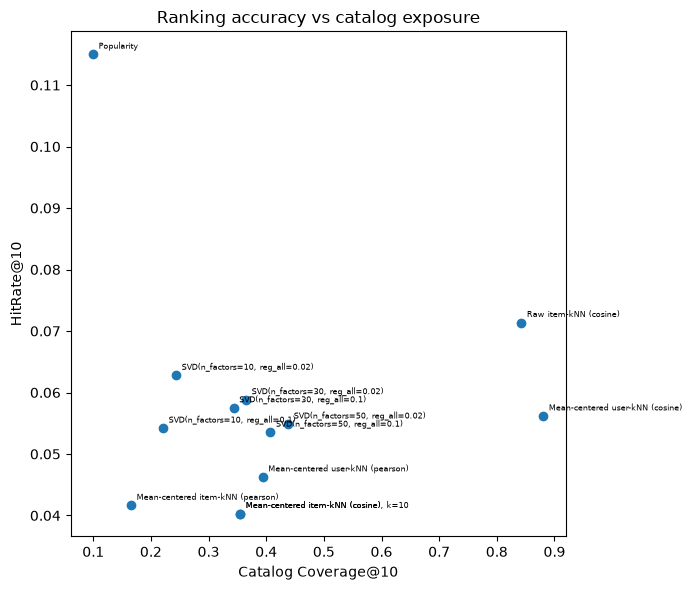

In [ ]:
# TODO(you) — Task 4: summary table + HitRate-vs-Catalog-Coverage scatter.
summary_rows = [{"model": "Popularity", "RMSE": np.nan, **pop_scores}] # Initialize the summary rows with the popularity model's scores
summary_rows += knn_results.to_dict("records") #Add the kNN models' scores to the summary rows
summary_rows += mf_results[["model", "RMSE", "HitRate@K", "NDCG@K", "Coverage@K"]].to_dict("records") #Add the matrix factorization models' scores to the summary rows
summary = pd.DataFrame(summary_rows) # Create a DataFrame from the summary rows
display(summary)

plt.figure(figsize=(7, 6))
plt.scatter(summary["Coverage@K"], summary["HitRate@K"])
for _, row in summary.iterrows():
    plt.annotate(row["model"], (row["Coverage@K"], row["HitRate@K"]),
                 fontsize=6, xytext=(4, 4), textcoords="offset points")
plt.xlabel("Catalog Coverage@10")
plt.ylabel("HitRate@10")
plt.title("Ranking accuracy vs catalog exposure")
plt.tight_layout()
plt.show()


#HitRate: Did we recommend the product the user actually rated later? higher is better
# #Coverage: How many different products did our system recommend across all users? higher is better
#RMSE: How close were our predicted star ratings to the actual ratings? lower is better
#NDCG: How high did we place the hidden product in our recommendation list? higher is better

How should we choose?
Scenario 1: Our priority is finding products users are likely to rate.

Choose Popularity, because it has the highest HitRate (11.50%).

The disadvantage is that it repeatedly recommends a small selection of products.

Scenario 2: Our priority is giving more products exposure.

Choose User-KNN (cosine), because it covers 88.07% of the catalogue.

But it has a lower HitRate.

Scenario 3: We want a balance between the two.

I would choose Raw item-KNN (cosine) as a reasonable compromise.

Why?

It covers 84.26% of the catalogue, nearly as much as user-KNN's 88.07%, but has a better HitRate: 7.14% instead of 5.62%.

So we're giving up only a little Coverage to improve HitRate.

### Task 4b - Does the overall score hide differences? (required)

Compare **HitRate@10 and NDCG@10 by the popularity of the hidden target item**.
Use popularity, the kNN model with the highest overall HitRate@10 and the SVD model with the
highest overall HitRate@10. Keep those three models fixed across groups.

The given code makes Low, Medium and High groups using each item's number of **training ratings**.
The cutoffs are the 1/3 and 2/3 quantiles across training items. Items with the same count stay
together, so groups may have different sizes or be empty. These labels describe your prepared
subset, not all Amazon items.

Only the results are split into groups. **Do not change candidate lists, retrain models or rank
only items from one group.** A user's group depends on their hidden item, not their recommendations.
The tables below reuse the per-user results you saved in Tasks 1-3.

In [ ]:
# Group items by training popularity (given). Preparation for Task 5. We will categorize items into Low, Medium, and High popularity based on their rating counts in the training set. This will help us analyze how well our recommendation models perform across different levels of item popularity.
training_counts = train_df['item'].value_counts() #Count the number of ratings for each item in the training set. This will be used to determine the popularity of each item.
low_cutoff, high_cutoff = training_counts.quantile([1 / 3, 2 / 3]) #Calculate the 1/3 and 2/3 quantiles of the item rating counts. Items with counts below the 1/3 quantile will be considered Low popularity, those between the 1/3 and 2/3 quantiles will be Medium popularity, and those above the 2/3 quantile will be High popularity.
group_order = ['Low', 'Medium', 'High']
item_group = {}
for item, count in training_counts.items():
    if count <= low_cutoff: #if the count of ratings for the item is less than or equal to the low cutoff, categorize it as Low popularity
        item_group[item] = 'Low'
    elif count <= high_cutoff:
        item_group[item] = 'Medium'
    else:
        item_group[item] = 'High'
print(f'Low: count <= {low_cutoff:g}; Medium: <= {high_cutoff:g}; High: > {high_cutoff:g}')

Low: count <= 6; Medium: <= 9; High: > 9


In [ ]:
# Show both catalogue size and the number of evaluated targets (given).
target_groups = pop_details['item'].map(item_group)
group_counts = pd.DataFrame({
    'Catalogue items': pd.Series(item_group).value_counts(),
    'Validation targets': target_groups.value_counts(),
}).reindex(group_order).fillna(0).astype(int)
display(group_counts)

selected_models = {
    'Popularity': 'Popularity',
    'kNN': knn_results.sort_values('HitRate@K', ascending=False, kind='stable').iloc[0]['model'],
    'SVD': mf_results.sort_values('HitRate@K', ascending=False, kind='stable').iloc[0]['model'],
}
display(pd.Series(selected_models, name='Selected model').to_frame())
#Does the popularity recommender achieve a higher HitRate for products with 10 or more ratings than for products with only 1–6 ratings?

#The next step will group users according to the popularity of their hidden product, then compare the models' HitRate and NDCG within each group.

,Catalogue items,Validation targets
Low,436,578
Medium,233,261
High,303,674


,Selected model
Popularity,Popularity
kNN,Raw item-kNN (cosine)
SVD,"SVD(n_factors=10, reg_all=0.02)"


In [ ]:
# Average the saved per-user scores within each target group (given).
group_rows = []
for label, name in selected_models.items():
    details = ranking_details[name].copy()
    details['group'] = details['item'].map(item_group)
    for group in group_order:
        rows = details[details['group'] == group]
        group_rows.append({'model': label, 'group': group, 'targets': len(rows),
                           'HitRate@K': rows['hit'].mean(), 'NDCG@K': rows['ndcg'].mean()})
group_results = pd.DataFrame(group_rows)
display(group_results.round(4))
#Do our recommendation models work better for popular products than for less-popular products?

,model,group,targets,HitRate@K,NDCG@K
0,Popularity,Low,578,0.0000,0.0000
1,Popularity,Medium,261,0.0000,0.0000
2,Popularity,High,674,0.2582,0.1272
3,kNN,Low,578,0.0346,0.0145
4,kNN,Medium,261,0.0651,0.0286
5,kNN,High,674,0.1053,0.0455
6,SVD,Low,578,0.0000,0.0000
7,SVD,Medium,261,0.0421,0.0166
8,SVD,High,674,0.1246,0.0566


What do these results mean?
Popularity: It retrieves no hidden products from the Low or Medium groups in this experiment. Its overall success comes entirely from High-popularity products.

KNN: It retrieves some hidden products even from the Low-popularity group. Its HitRate increases from 3.46% for Low to 10.53% for High.

SVD: It retrieves no Low-popularity hidden products in this experiment, but performs better for Medium and High groups.

All three models perform best on High-popularity hidden products, although the relative strengths differ by group.
5. WHY is this important?
Remember Task 4, when we concluded that popularity had the highest overall HitRate?

Now we discover something more specific:

Popularity is best overall largely because it performs very well for highly rated-count products, not because it works equally well for every product.

KNN has a lower overall HitRate, but it is the only one of these three models that retrieves any Low-popularity hidden products.

This is why averages can sometimes hide important differences.
Based on your actual results, all three models are most successful at retrieving High-popularity products (products with 10 or more training ratings).

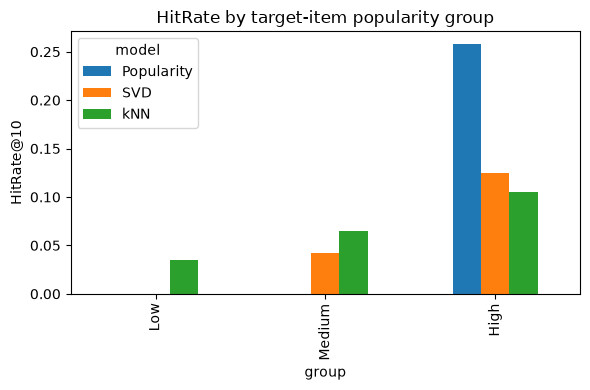

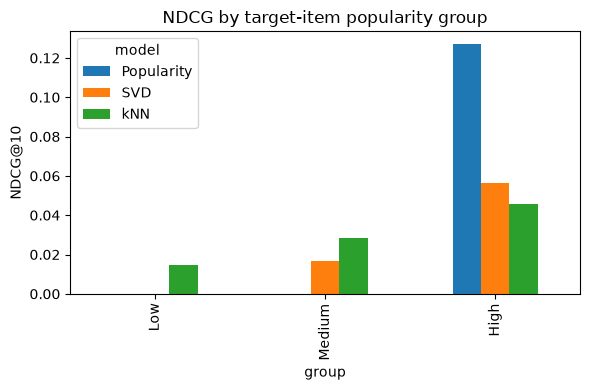

In [33]:
# TODO(you) — Task 4b: two popularity-group bar charts.
# Use group_results. Make one chart for HitRate@10 and one for NDCG@10.
# Put Low, Medium, High on the x-axis, with one bar per model in each group.
# Hint: group_results.pivot(index='group', columns='model', values='HitRate@K')
#       .reindex(group_order) gives the table for the first chart; use .plot.bar(...).
# Keep the group_counts table visible. Missing scores mean no targets, not zero accuracy.
# TODO(you) — Task 4b: two popularity-group bar charts.
hit_table = group_results.pivot(index='group', columns='model', values='HitRate@K').reindex(group_order)
hit_table.plot.bar(figsize=(6, 4))
plt.ylabel("HitRate@10")
plt.title("HitRate by target-item popularity group")
plt.tight_layout()
plt.show()

ndcg_table = group_results.pivot(index='group', columns='model', values='NDCG@K').reindex(group_order)
ndcg_table.plot.bar(figsize=(6, 4))
plt.ylabel("NDCG@10")
plt.title("NDCG by target-item popularity group")
plt.tight_layout()
plt.show()

1. How do we read this?

The X-axis shows the popularity of the hidden product.

The Y-axis shows the percentage of users whose hidden product appeared in the top 10.

We can see that Popularity performs best for High-popularity products, but doesn't retrieve any Low- or Medium-popularity hidden products. KNN is the only one of the three that retrieves some Low-popularity hidden products.
    
    2. second plot : But the Y-axis is different: NDCG measures how successfully we retrieve the hidden product while also rewarding higher ranking positions.

For example, Popularity has an NDCG of 0.1272 for High-popularity targets, higher than KNN's 0.0455 and SVD's 0.0566.

That means Popularity has the strongest average position-weighted retrieval score for that group.
    

	First plot	Second plot
Metric	HitRate@10	NDCG@10
Main question	Did the model find the hidden item?	Did the model find it and rank it highly?
Higher is better?	Yes	Yes
What changes in code?	values='HitRate@K'	values='NDCG@K'

Both plots show a similar pattern: the models perform better when the hidden target product is more popular.
5. What should we conclude for the lab?
The two plots show that recommendation performance depends strongly on product popularity. Popularity performs best for High-popularity products, but fails to retrieve hidden products in the Low and Medium groups. KNN retrieves some Low-popularity products and has the highest HitRate and NDCG for the Medium group. SVD performs better for High-popularity products than for less-popular ones, but remains below Popularity in that group.

The most important connection to Task 4: Popularity had the best overall HitRate, but these plots show where that success comes from. It is not equally successful across different product-popularity groups.

--------------------------------------

**Task 4 interpretation and recommendation (5-7 sentences).** Compare ranking
accuracy and catalog coverage. Does the overall winner also win in each popularity group?
Use the target counts to explain which group most affects the overall score. The overall score
is a weighted average of group scores, not an equal average of the three groups. An empty group
has no score; a group with few targets provides weak evidence.
Choose one model for a stated objective and give one limitation. These validation comparisons
help you explore the models; they do not prove which model would work best for new users.

> ...
>
> The HitRate-vs-Coverage scatter shows Popularity achieving the best overall HitRate@10 (0.115) but the lowest Coverage@10 (0.10), while Raw item-kNN (cosine) offers a strong alternative trade-off: nearly as good HitRate (0.071) with far higher coverage (0.84). Most SVD and other kNN variants cluster in a middle band with modest HitRate (0.04–0.06) and moderate coverage (0.17–0.44), not clearly differentiated from each other.

The popularity-group breakdown reveals that Popularity's overall win is misleading: it scores 0 on both Low and Medium target groups, since it always recommends the same fixed best-sellers regardless of the user, and achieves its entire 0.115 HitRate by dominating only the High group (HitRate 0.258), which holds 674 of 1,513 validation targets (~45%) — the largest and most heavily weighted group. SVD similarly scores 0 on the Low group. Raw item-kNN (cosine) is the only model that retrieves any Low-popularity targets at all (HitRate 0.035), making it the only one of the three capable of surfacing less-common items to users at all.

For an objective of maximizing overall retrieval accuracy on this data, Popularity is hard to beat given how concentrated the target distribution is toward popular items. But for an objective of exposing users to a wider range of the catalog, especially less-popular items, Raw item-kNN (cosine) is a clearly better choice: it retains most of Popularity's high-group performance while being the only model that works at all outside it. One limitation: with only 578 Low-group and 261 Medium-group targets (versus 674 High), the Low/Medium scores are based on fewer observations and are less statistically robust than the High-group scores, so these group differences, while consistent with the model's design, should be interpreted as directional rather than precise.

## Task 5 — Embedding visualization
**Your turn.** Project the learned item factors to 2D with PCA and annotate
several popular items with their titles. Report the combined explained variance of PC1 and PC2.
Do the nearby items make sense in your category? Write 3-5 sentences of interpretation.

**Reading PCA:** each row of `Q` is one item's learned vector. PCA centers these vectors and
finds directions with the greatest variation. PC1 and PC2 give the two plotting coordinates.
The axes are combinations of factors, not named genres. If there are more than two factors,
the projection loses information and can make different items look close.
No clear clusters is a valid finding. A plausible plot does not prove recommendation quality.

In [ ]:
# --- Item-factor extraction helper (given; you complete the analysis).
def get_item_factors(fitted_svd, train_df): 
    """Return (asins, Q) where Q[i] is the latent vector of asins[i], for a FITTED SVD."""
    ts = fitted_svd.trainset
    asins, rows = [], []
    for raw in train_df["item"].unique():
        try:
            rows.append(fitted_svd.qi[ts.to_inner_iid(raw)])
            asins.append(raw)
        except (ValueError, KeyError):
            continue
    return asins, np.vstack(rows)

Remember Task 2B, where KNN said an RV water hose was similar to car wax and other unrelated products?

Task 5 investigates a related question using SVD:

Do the product vectors learned by SVD show meaningful relationships when visualized?

The idea is that products with similar learned profiles may appear near one another.

But we're careful: PCA is only a 2D projection. Two products appearing close in the plot doesn't necessarily mean they're similar in every original dimension or functionally related.
5. What is the output of this cell?
Nothing yet. It only defines the function get_item_factors().

The next cell will call it, obtain the matrix Q, apply PCA and draw the graph.

Main takeaway: This first cell is a helper. It extracts the learned product vectors from SVD and preserves their product IDs so we can visualize them in the next step.

Variation retained: 0.22653295279618796


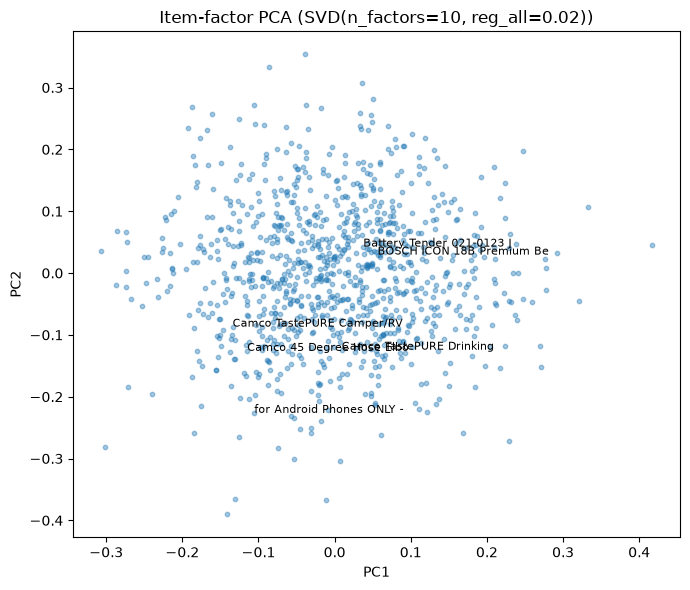

In [35]:
# TODO(you) — Task 5: 2D projection + annotated scatter.
# from sklearn.decomposition import PCA
# best_name = mf_results.sort_values("HitRate@K", ascending=False).iloc[0]["model"]
# best_mf_model = mf_models[best_name]  # already fitted by fit_and_evaluate_surprise
# asins, Q = get_item_factors(best_mf_model, train_df)
# pca = PCA(n_components=2)
# xy = pca.fit_transform(Q)
# print("Variation retained:", pca.explained_variance_ratio_.sum())
# project to 2D, scatter, and annotate ~5 POPULAR items via titles_map.
# TODO(you) — Task 5: 2D projection + annotated scatter.
best_name = mf_results.sort_values("HitRate@K", ascending=False).iloc[0]["model"]
best_mf_model = mf_models[best_name]  # already fitted by fit_and_evaluate_surprise
asins, Q = get_item_factors(best_mf_model, train_df)

pca = PCA(n_components=2)
xy = pca.fit_transform(Q)
print("Variation retained:", pca.explained_variance_ratio_.sum())

asin_to_idx = {a: i for i, a in enumerate(asins)}
item_pop = train_df["item"].value_counts()
popular_titled = [a for a in item_pop.index if a in asin_to_idx and a in titles_map][:6]

plt.figure(figsize=(7, 6))
plt.scatter(xy[:, 0], xy[:, 1], s=10, alpha=0.4)
for a in popular_titled:
    idx = asin_to_idx[a]
    plt.annotate(titles_map[a][:25], (xy[idx, 0], xy[idx, 1]), fontsize=8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"Item-factor PCA ({best_name})")
plt.tight_layout()
plt.show()

*Your interpretation of the embedding plot (3–5 sentences) — write it here:*

> ...
> The two principal components retain only about 22.7% of the variance in the 10-dimensional item factors, so this 2D view necessarily discards most of the learned structure. The projected items form one dense, roughly uniform cloud with no visible separation into distinct clusters, popular titled items like the Battery Tender charger and Camco RV products sit centrally, close to many unrelated items, rather than forming a recognizable neighborhood of similar products. This lack of clear clustering is consistent with the Task 2b neighbor inspection, where nearest neighbors of specific items were often functionally unrelated products, both results point to the same underlying cause: with nearly 9 ratings per item on average, the model doesn't have enough signal to learn strongly differentiated, semantically meaningful item representations. A plot on its own would not prove the embeddings are meaningful; the lack of structure here is itself informative about the limits of this sparse dataset.

## AI-use declaration
Replace the line below. Name each AI tool used and its purpose, or write **No AI tools used**.

> ...
> Claude LLM
> Gemini LLM